# S07b: S07 with wider no-trade bands and no trading in the first 30 minutes

Pre-registration: [`007_claude_s07b_wide_bands.md`](../../discussions/Residual_Reversion/007_claude_s07b_wide_bands.md). Engine: `src/equity_trading/s07.py` (unchanged except `skip_open_bars`).

Same book as S07. Changes, both cost-driven: bands of 1.5× and 2.0× the average position, and no fills at the 09:30 and 09:45 opens (orders wait for 10:00). Reference (not judged): S07's `band10` with the open skip.

In [1]:
N_PLACEBO = 300              # per arm; gates use alpha = 0.025 (two arms)
N_JOBS = -1
PER_YEAR, WINDOW_S = 4, 3.0  # S05b quote samples (reused from the cache)

import json, os, sys, time
from dataclasses import replace
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import __version__, s04, s05, s05b, s07
from equity_trading.alpaca import ALPACA_VERSION, download_years, sample_quote_spreads
from equity_trading.data import vendor_dir, work_dir

SYNTHETIC = os.environ.get("S07_SYNTHETIC") == "1"
YEARS = list(range(2020, 2026))                      # 2026 not used
CFG = s07.S07Config(n_placebo=N_PLACEBO, skip_open_bars=2)
ARMS = {"band15": 1.5, "band20": 2.0}
REF = {"band10skip": 1.0}
if SYNTHETIC:
    YEARS, N_PLACEBO = [2024, 2025], 10
    CFG = replace(CFG, w_cap=0.05)                   # 40 synthetic stocks: average weight 2.5%

tag = ("synthetic_" if SYNTHETIC else "") + f"alpaca{ALPACA_VERSION}_s07{s07.S07_VERSION}_p{s04.PANEL_VERSION}"
OUT = ROOT / "notebooks" / "Residual_Reversion" / ("07b_synthetic" if SYNTHETIC else "07b")
OUT.mkdir(parents=True, exist_ok=True)
CACHE = work_dir() / "results" / "s07b" / tag
CACHE.mkdir(parents=True, exist_ok=True)
QUOTE_CACHE = vendor_dir("Alpaca") / "quote_samples" / f"{CFG.timeframe}_w{WINDOW_S:g}s"
QUOTE_CACHE.mkdir(parents=True, exist_ok=True)

COL = {"band15": "#2a78d6", "band20": "#1baf7a", "band10skip": "#eb6834", "grey": "#8a8a84"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.titleweight": "bold", "font.size": 9})

if SYNTHETIC:
    from equity_trading.universe import SECTOR_ETF_01, UNIVERSE_01
    ETF_OF = {s: SECTOR_ETF_01[k] for k, v in UNIVERSE_01.items() for s in v}
    BENCH = "XLK"
else:
    constituents = pd.read_csv(ROOT / "src" / "equity_trading" / "reference" / "sp500_constituents_20260913.csv")
    ETF_OF = dict(zip(constituents["Symbol"], constituents["GICS Sector"].map(s05.SECTOR_ETF)))
    BENCH = "SPY"
STOCKS = sorted(ETF_OF)
ETFS = sorted(set(ETF_OF.values()))
print(f"synthetic={SYNTHETIC} | stocks={len(STOCKS)} | arms={ARMS} | placebos per arm={N_PLACEBO}")
print(CFG)

synthetic=False | stocks=503 | arms={'band15': 1.5, 'band20': 2.0} | placebos per arm=300
S07Config(timeframe='15Min', ffill_bars=2, window_sessions=20, min_bar_share=0.95, max_tau_frac=0.5, center_m=True, s_cap=3.0, gross=1.0, w_cap=0.02, band_mult=1.0, etf_band=0.001, skip_open_bars=2, initial_equity=100000.0, cost_mult=1.0, n_placebo=300, seed=42)


## 1. Data and measured costs

In [2]:
t0 = time.time()
if SYNTHETIC:
    panel, _ = s04.synthetic_ohlc_panel(YEARS)
else:
    download_years(STOCKS + ETFS + [BENCH], CFG.timeframe, YEARS, workers=8)
    panel = s04.cached_panel(STOCKS + ETFS + [BENCH], CFG.timeframe, YEARS, ffill_bars=CFG.ffill_bars)
have = set(panel.symbols)
TRADED = [s for s in STOCKS if s in have and ETF_OF[s] in have]
SC = np.array([panel.symbols.index(s) for s in TRADED])
EC = np.array([panel.symbols.index(ETF_OF[s]) for s in TRADED])
QUOTED = sorted(set(TRADED) | {ETF_OF[s] for s in TRADED})
print(f"panel {panel.c.shape} in {time.time() - t0:.0f}s | traded stocks {len(TRADED)}")
SESSIONS = s05b.sample_sessions(YEARS, PER_YEAR, seed=42)
if SYNTHETIC:
    samples = pd.DataFrame([(s, 3e-4, 10, k, d) for d in SESSIONS for k in range(26) for s in QUOTED],
                           columns=["symbol", "half_spread", "n_quotes", "slot", "date"])
else:
    missing = [d for d in SESSIONS if not (QUOTE_CACHE / f"{d}.parquet").exists()]
    print(f"quote sessions cached: {len(SESSIONS) - len(missing)}/{len(SESSIONS)}")
    for d in missing:
        sample_quote_spreads(QUOTED, d, s05b.slot_starts(YEARS, d), window_s=WINDOW_S, cache_dir=QUOTE_CACHE)
    samples = pd.concat([pd.read_parquet(QUOTE_CACHE / f"{d}.parquet") for d in SESSIONS], ignore_index=True)
H = s05b.cost_array(panel.index, panel.day_start, panel.symbols, s05b.cost_model(samples))
print(f"measured half-spread: stocks {np.median(H[:, SC]) * 1e4:.2f} bps, ETFs {np.median(H[:, np.unique(EC)]) * 1e4:.2f} bps")

est_path = CACHE / "params.npz"
if est_path.exists():
    P = dict(np.load(est_path))
else:
    t0 = time.time(); P = s05.estimate_all(panel, SC, EC, CFG.s05(), s07.first_decision_day(CFG))
    np.savez(est_path, **P); print(f"estimated in {time.time() - t0:.0f}s")

15Min: 0 batches to download (0 symbol-years), 8 parallel requests
panel (39064, 513) in 8s | traded stocks 501
quote sessions cached: 24/24
measured half-spread: stocks 3.01 bps, ETFs 0.65 bps
estimated in 49s


## 2. Backtests

Each arm at 1×, 2× and 0× measured cost, plus the reference `band10skip` (S07 band 1.0 with the open skip; reported only).

8 backtests in 1.3 min; trading starts 2020-02-03


,total_return,sharpe,max_drawdown,mean_daily,days,annual_turnover_x_equity,annual_cost_pct_equity,stock_trades_per_day,avg_gross_exposure,ann_return_per_unit_gross
band15 1x,0.0049,0.0476,0.0614,0.0000,1486.0,74.9999,2.4221,182.7687,0.9354,0.0009
band15 2x,-0.1237,-0.6998,0.1572,-0.0001,1486.0,74.9346,4.7755,175.6994,NaN,-0.0237
band15 0x,0.1593,0.8180,0.0598,0.0001,1486.0,74.7160,0.0000,189.6577,NaN,0.0271
band20 1x,0.0037,0.0452,0.0394,0.0000,1486.0,39.1200,1.2121,94.1237,0.7183,0.0009
band20 2x,-0.0707,-0.6108,0.0966,-0.0000,1486.0,39.0222,2.4007,92.1748,NaN,-0.0172
band20 0x,0.0807,0.6689,0.0386,0.0001,1486.0,39.0295,0.0000,95.8843,NaN,0.0184
band10skip 1x,-0.0432,-0.1589,0.0910,-0.0000,1486.0,133.0077,4.4923,328.5568,1.0665,-0.0070
band10skip 0x,0.2609,0.9946,0.0756,0.0002,1486.0,132.2912,0.0000,354.2730,NaN,0.0376


,total_return,sharpe,annual_turnover_x_equity,annual_cost_pct_equity
S07 (no open skip),,,,
band05 1x,-0.3412,-1.5053,277.7017,11.8264
band10 1x,-0.1015,-0.4183,142.9435,5.8598
band05 0x,0.3478,1.1184,272.3138,0.0000
band10 0x,0.2858,1.0656,141.7705,0.0000


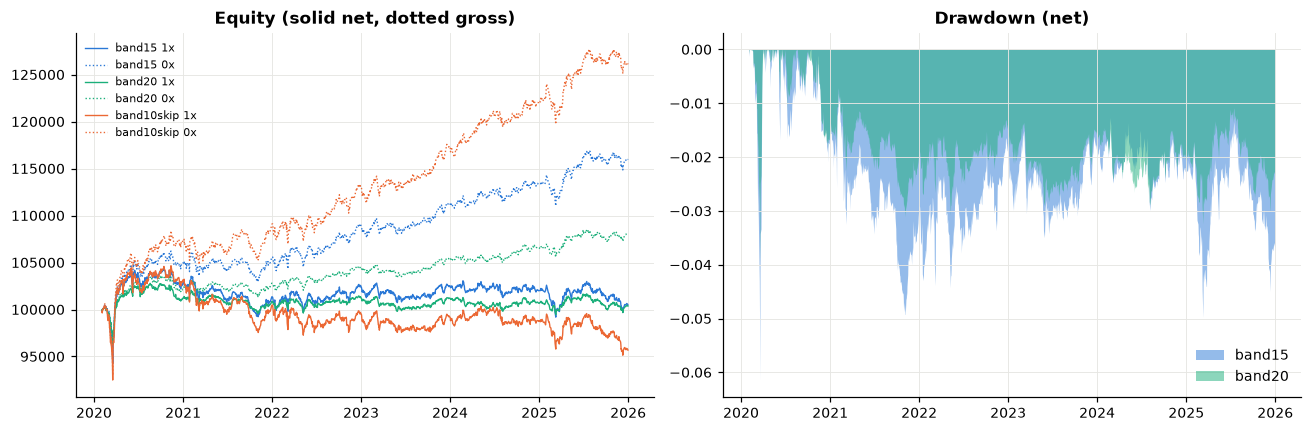

,2020,2021,2022,2023,2024,2025
band15,0.0275,-0.0136,0.0119,-0.0003,-0.0052,-0.0148
band20,0.0121,-0.0034,0.0048,-0.0013,-0.0057,-0.0028


In [3]:
runs = {}
t0 = time.time()
for arm, bm in {**ARMS, **REF}.items():
    for cm in (1.0, 2.0, 0.0):
        if arm in REF and cm == 2.0:
            continue
        runs[(arm, cm)] = s07.backtest(panel, P, SC, EC, H, replace(CFG, band_mult=bm, cost_mult=cm), record=(cm == 1.0))
START = runs[("band15", 1.0)]["first_day"]
print(f"{len(runs)} backtests in {(time.time() - t0) / 60:.1f} min; trading starts {START.date()}")
rows = {}
for (arm, cm), r in runs.items():
    m = s04.perf_metrics(r["daily_equity"], CFG.initial_equity, START)
    ts = s07.turnover_stats(r, START, CFG.initial_equity)
    rows[f"{arm} {cm:g}x"] = {**m, **ts}
for arm in [*ARMS, *REF]:
    g = runs[(arm, 1.0)]["gross_exposure"]
    eq = runs[(arm, 1.0)]["bar_equity"].to_numpy()
    live = g > 0
    rows[f"{arm} 1x"]["avg_gross_exposure"] = float(np.mean(g[live] / eq[live]))
metrics = pd.DataFrame(rows).T
gx = metrics["avg_gross_exposure"].groupby(lambda k: k.split()[0]).transform("max")
metrics["ann_return_per_unit_gross"] = ((1 + metrics["total_return"]) ** (252 / metrics["days"].clip(lower=1)) - 1) / gx
display(metrics.round(4))
s07_path = ROOT / "notebooks" / "Residual_Reversion" / "07" / "summary.json"
if s07_path.exists() and not SYNTHETIC:
    ref = json.loads(s07_path.read_text())["metrics"]
    display(pd.DataFrame({k: ref[k] for k in ["band05 1x", "band10 1x", "band05 0x", "band10 0x"]}).T
            [["total_return", "sharpe", "annual_turnover_x_equity", "annual_cost_pct_equity"]].round(4).rename_axis("S07 (no open skip)"))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for arm in [*ARMS, *REF]:
    for cm, ls in ((1.0, "-"), (0.0, ":")):
        e = runs[(arm, cm)]["daily_equity"]; e = e[e.index >= START]
        ax[0].plot(e.index, e, color=COL[arm], ls=ls, lw=0.9, label=f"{arm} {cm:g}x")
ax[0].set_title("Equity (solid net, dotted gross)"); ax[0].legend(frameon=False, fontsize=7)
for arm in ARMS:
    e = runs[(arm, 1.0)]["daily_equity"]; e = e[e.index >= START]
    ax[1].fill_between(e.index, e / e.cummax() - 1, 0, color=COL[arm], alpha=0.5, lw=0, label=arm)
ax[1].set_title("Drawdown (net)"); ax[1].legend(frameon=False)
plt.tight_layout(); plt.show()
by_year = {}
for arm in ARMS:
    e = runs[(arm, 1.0)]["daily_equity"]; e = e[e.index >= START]
    ye = e.groupby(e.index.year).last()
    by_year[arm] = ye / ye.shift(1).fillna(CFG.initial_equity) - 1
display(pd.DataFrame(by_year).T.round(4))
for arm in ARMS:
    runs[(arm, 1.0)]["daily_equity"].to_csv(OUT / f"daily_equity_{arm}.csv", header=["equity"], float_format="%.2f")

## 3. Placebo: shuffled signal (each day, stocks receive another tradable stock's s-score path)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  28 tasks      | elapsed:  2.6min
[Parallel(n_jobs=-1)]: Done 136 tasks      | elapsed: 10.4min
[Parallel(n_jobs=-1)]: Done 300 out of 300 | elapsed: 22.5min finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 4 concurrent workers.


band15: 300 placebos in 22.5 min


[Parallel(n_jobs=-1)]: Done  28 tasks      | elapsed:  2.3min
[Parallel(n_jobs=-1)]: Done 136 tasks      | elapsed:  9.9min


band20: 300 placebos in 21.8 min


[Parallel(n_jobs=-1)]: Done 300 out of 300 | elapsed: 21.8min finished


value  percentile  p_upper  placebo_median  placebo_p95
band15 total_return  0.0049       100.0   0.0033         -0.2513      -0.2267
       sharpe        0.0476       100.0   0.0033         -4.6437      -4.0577
band20 total_return  0.0037       100.0   0.0033         -0.1155      -0.0939
       sharpe        0.0452       100.0   0.0033         -2.4627      -1.9235

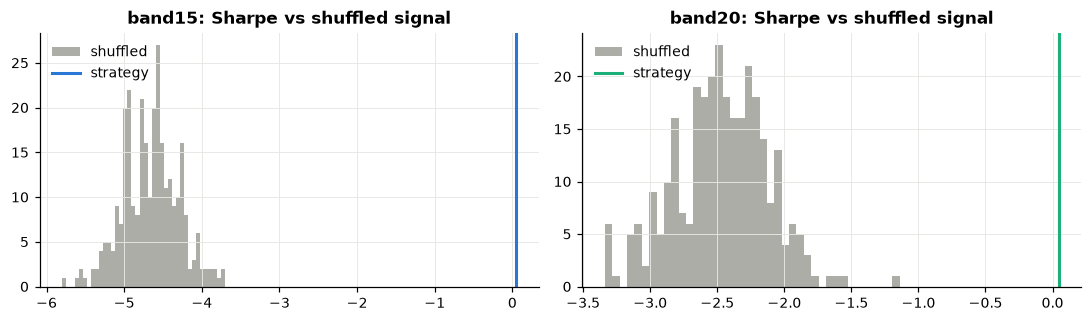

In [4]:
from joblib import Parallel, delayed
placebos, ranks = {}, {}
for arm, bm in ARMS.items():
    cfg_a = replace(CFG, band_mult=bm)
    pl_path = CACHE / f"placebo_shuffle_{arm}_{N_PLACEBO}.parquet"
    if pl_path.exists():
        pl = pd.read_parquet(pl_path)
    else:
        t0 = time.time()
        pl = pd.DataFrame(Parallel(n_jobs=N_JOBS, batch_size=2, verbose=5)(
            delayed(s07.run_placebo)(panel, P, SC, EC, H, cfg_a, CFG.seed * 1000 + i, START) for i in range(N_PLACEBO)))
        pl.to_parquet(pl_path); print(f"{arm}: {N_PLACEBO} placebos in {(time.time() - t0) / 60:.1f} min")
    pl.to_csv(OUT / f"placebo_shuffle_{arm}.csv", index=False, float_format="%.6g")
    placebos[arm] = pl
    bm_ = metrics.loc[f"{arm} 1x"]
    ranks[arm] = {k: s04.placebo_rank(bm_[k], pl[k].to_numpy()) for k in ("total_return", "sharpe")}
display(pd.concat({a: pd.DataFrame(v).T for a, v in ranks.items()}).round(4))
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
for i, arm in enumerate(ARMS):
    ax[i].hist(placebos[arm]["sharpe"], bins=40, color=COL["grey"], alpha=0.7, label="shuffled")
    ax[i].axvline(metrics.loc[f"{arm} 1x", "sharpe"], color=COL[arm], lw=2, label="strategy")
    ax[i].set_title(f"{arm}: Sharpe vs shuffled signal"); ax[i].legend(frameon=False)
plt.tight_layout(); plt.show()

## 4. Bootstrap, market exposure, gates

In [5]:
days = pd.to_datetime(panel.days)
bench_close = pd.Series(panel.c[panel.day_start[1:] - 1, panel.symbols.index(BENCH)], index=days)
G, boots, mkts = {}, {}, {}
for arm in ARMS:
    e = runs[(arm, 1.0)]["daily_equity"]; e = e[e.index >= START]
    rd = e.pct_change().dropna().to_numpy()
    boots[arm] = {b: s04.block_bootstrap_mean(rd, b, 10_000, CFG.seed) for b in (10, 20, 40)}
    mkts[arm] = s04.market_regression(e, bench_close)
    G[arm] = s07.gates(boots[arm], ranks[arm], metrics.loc[f"{arm} 2x"].to_dict(), metrics.loc[f"{arm} 1x"].to_dict())
display(pd.concat({a: pd.DataFrame(b, index=["mean", "lo95", "hi95"]).T for a, b in boots.items()}))
print("market regression vs", BENCH, {a: {k: round(v, 5) for k, v in m.items()} for a, m in mkts.items()})
display(pd.DataFrame(G))
summary = {"study": "S07b", "synthetic": SYNTHETIC, "years": YEARS, "config": CFG.as_dict(), "arms": ARMS, "reference": REF,
           "trading_start": str(START.date()), "n_placebo_per_arm": N_PLACEBO, "metrics": metrics.to_dict(orient="index"),
           "placebo_shuffle_ranks": ranks, "bootstrap": {a: {str(k): v for k, v in b.items()} for a, b in boots.items()},
           "market": mkts, "gates": G,
           "versions": {"package": __version__, "alpaca": ALPACA_VERSION, "s05": s05.S05_VERSION, "s07": s07.S07_VERSION,
                        "panel": s04.PANEL_VERSION}}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=float))
(OUT / "manifest.json").write_text(json.dumps({"files": sorted(p.name for p in OUT.iterdir()), "cache": str(CACHE)}, indent=2))
print(json.dumps({a: {k: g[k] for k in ["statistical_verdict", "economic_verdict", "verdict"]} for a, g in G.items()}, indent=2))

mean      lo95      hi95
band15 10  0.000006 -0.000101  0.000121
       20  0.000006 -0.000098  0.000114
       40  0.000006 -0.000064  0.000109
band20 10  0.000004 -0.000067  0.000077
       20  0.000004 -0.000064  0.000073
       40  0.000004 -0.000043  0.000068

market regression vs SPY {'band15': {'alpha_daily': -2e-05, 'alpha_p': 0.75027, 'beta': 0.03491, 'r2': 0.05429, 'n': 1486}, 'band20': {'alpha_daily': -1e-05, 'alpha_p': 0.7434, 'beta': 0.02266, 'r2': 0.05606, 'n': 1486}}


,band15,band20
G1_bootstrap,False,False
G2_vs_shuffled_signal,True,True
G3_double_cost,False,False
statistical_verdict,PARTIAL,PARTIAL
economic_verdict,NOT_PROFITABLE_AFTER_COSTS,NOT_PROFITABLE_AFTER_COSTS
verdict,NO_EDGE,NO_EDGE


{
  "band15": {
    "statistical_verdict": "PARTIAL",
    "economic_verdict": "NOT_PROFITABLE_AFTER_COSTS",
    "verdict": "NO_EDGE"
  },
  "band20": {
    "statistical_verdict": "PARTIAL",
    "economic_verdict": "NOT_PROFITABLE_AFTER_COSTS",
    "verdict": "NO_EDGE"
  }
}
